In [ ]:
!pip install pandas numpy openai sentence-transformers datasets transformers[torch] accelerate>=1.1.0 seaborn hdbscan umap-learn nltk plotly optuna BERTopic "git+https://github.com/FelSiq/DBCV"

In [1]:
%load_ext cuml.accel

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuML: Installed accelerator for sklearn.
cuML: Installed accelerator for umap.
cuML: Installed accelerator for hdbscan.
cuML: Successfully initialized accelerator.


In [2]:
import pandas as pd
import numpy as np
import os
import json
from tqdm import tqdm
from pydantic import BaseModel, Field
from typing import Literal
from openai import OpenAI
import random
import torch
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import safetensors
import umap
import hdbscan
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import plotly.express as px
import plotly.graph_objects as go
import textwrap
import gc
import re
import requests
import html
import re
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForSequenceClassification

In [3]:
pd.set_option('display.max_columns', None)

In [4]:
df_speech = pd.read_csv("filtered_speech_level_data.csv")
df_speech.shape

(3141, 35)

# HDBSCAN

We perform clustering on the UMAP embeddings using HDBSCAN to get the final clusters of speeches.

In [5]:
from safetensors import safe_open

tensors = {}
with safe_open("speech_embeddings.safetensors", framework="pt", device=0) as f:
    for k in f.keys():
        tensors[k] = f.get_tensor(k)
with safe_open("enriched_embeddings.safetensors", framework="pt", device=0) as f:
    for k in f.keys():
        tensors[k] = f.get_tensor(k)

In [6]:
speech_embeddings = tensors["speech_embeddings"].cpu().numpy()
speech_embeddings.shape

(3141, 1024)

In [7]:
enriched_embeddings = tensors['enriched_embeddings'].cpu().numpy()
enriched_embeddings.shape

(3141, 1024)

In [8]:
# !rm study.db

In [9]:
# import optuna
# import dbcv
# import umap
# from sklearn.cluster import HDBSCAN
# import numpy as np

# def objective(trial):
#     # Run UMAP
#     reducer = umap.UMAP(
#         n_components=50,
#         metric='cosine',
#         random_state=42
#     )
#     low_dim_embeddings = reducer.fit_transform(enriched_embeddings)

#     min_cluster_size = trial.suggest_int('hdbscan_min_cluster_size', 2, 150)
#     min_samples = trial.suggest_int('hdbscan_min_samples', 1, min_cluster_size)
#     cluster_selection_epsilon = trial.suggest_float('hdbscan_cluster_selection_epsilon', 0.0, 0.5)
#     leaf_size = trial.suggest_int('leaf_size', 10, 100)

#     clusterer = HDBSCAN(
#         min_cluster_size=min_cluster_size,
#         min_samples=min_samples,
#         cluster_selection_method="leaf",
#         cluster_selection_epsilon=cluster_selection_epsilon,
#         leaf_size=leaf_size,
#         n_jobs=-1
#     )
#     clusterer.fit(low_dim_embeddings)
#     labels = clusterer.labels_

#     unique_clusters = set(labels) - {-1}
#     n_clusters = len(unique_clusters)
#     noise_ratio = np.mean(labels == -1)

#     dbcv_score = dbcv.dbcv(X=low_dim_embeddings, y=labels, n_processes=2)
#     final_score = dbcv_score - noise_ratio  # Adjusted score to penalize noise

#     trial.set_user_attr("n_clusters", n_clusters)
#     trial.set_user_attr("noise_ratio", noise_ratio)
#     trial.set_user_attr("raw_dbcv", dbcv_score)

#     return final_score

In [10]:
# study = optuna.create_study(direction="maximize")

In [11]:
# study.optimize(objective, n_trials=10, show_progress_bar=True)

In [12]:
# best_params = study.best_trial.params
# best_params

In [13]:
# from bertopic import BERTopic
# from sklearn.feature_extraction.text import CountVectorizer
# from bertopic.vectorizers import ClassTfidfTransformer
# from nltk.corpus import stopwords

# stop_words_multi = list(set(stopwords.words('german')).union(set(stopwords.words('french'))).union(set(stopwords.words('italian'))))

# umap_model = umap.UMAP(
#     n_components=50,
#     metric='cosine',
#     random_state=42
# )

# hdbscan_model = HDBSCAN(
#     min_cluster_size=best_params['hdbscan_min_cluster_size'],
#     min_samples=best_params['hdbscan_min_samples'],
#     cluster_selection_method="leaf",
#     cluster_selection_epsilon=best_params['hdbscan_cluster_selection_epsilon'],
#     leaf_size=best_params['leaf_size'],
#     n_jobs=-1
# )

# # CountVectorizer with custom stop words (German, French, Italian)
# vectorizer_model = CountVectorizer(
#     stop_words=stop_words_multi,
#     #min_df=2,
#     #max_df=0.6,
# )
# # TF-IDF transformer that reduces the importance of frequent words across topics
# ctfidf_model = ClassTfidfTransformer(reduce_frequent_words=True)

In [24]:
from bertopic import BERTopic
from sklearn.cluster import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.vectorizers import ClassTfidfTransformer
from nltk.corpus import stopwords

stop_words_multi = list(set(stopwords.words('german')).union(set(stopwords.words('french'))).union(set(stopwords.words('italian'))))

umap_model = umap.UMAP(
    n_components=50,
    metric='cosine',
    random_state=42
)

hdbscan_model = HDBSCAN(
    cluster_selection_method="leaf",
    n_jobs=-1,
)

# CountVectorizer with custom stop words (German, French, Italian)
vectorizer_model = CountVectorizer(
    stop_words=stop_words_multi,
    #min_df=2,
    #max_df=0.6,
)
# TF-IDF transformer that reduces the importance of frequent words across topics
ctfidf_model = ClassTfidfTransformer(reduce_frequent_words=True)

build_algo set to brute_force_knn because random_state is given


In [25]:
# Initialize BERTopic with the specified models and parameters
topic_model = BERTopic(
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,
    verbose=True,
)

# Find topics
topics, _ = topic_model.fit_transform(documents=df_speech['TEXT_SPAN'].tolist(), embeddings=speech_embeddings)

2026-07-06 14:07:58,338 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm


2026-07-06 14:07:58,636 - BERTopic - Dimensionality - Completed ✓
2026-07-06 14:07:58,637 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-07-06 14:07:58,957 - BERTopic - Cluster - Completed ✓
2026-07-06 14:07:58,961 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-07-06 14:07:59,954 - BERTopic - Representation - Completed ✓


In [26]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,1299,-1_erneuerbaren_energien_vs_eigentlich,"[erneuerbaren, energien, vs, eigentlich, schwe...",[Mit der parlamentarischen Initiative Girod so...
1,0,60,0_ehe_paare_samenspende_kinder,"[ehe, paare, samenspende, kinder, kind, gleich...","[Es freut mich, dass diese Debatte in dieser S..."
2,1,53,1_bureau_vote_conciliation_finaux,"[bureau, vote, conciliation, finaux, parlement...",[Le Bureau a mené une discussion approfondie s...
3,2,39,2_chiens_chien_dangereux_races,"[chiens, chien, dangereux, races, morsures, li...",[J'aimerais encore donner brièvement quelques ...
4,3,34,3_transparence_dons_campagne_partis,"[transparence, dons, campagne, partis, francs,...","[Si j'ai bien compté, il reste encore trois mi..."
...,...,...,...,...,...
127,126,5,126_pertinents_mtabolites_substances_dgradation,"[pertinents, mtabolites, substances, dgradatio...",[J'ai déjà eu l'occasion de le dire lors du dé...
128,127,5,127_nhg_731n_731k_1bis,"[nhg, 731n, 731k, 1bis, objekten, spezialitt, ...",[Durch die Verabschiedung von Artikel 731n ist...
129,128,5,128_werbung_branche_selbstregulierung_aggressiver,"[werbung, branche, selbstregulierung, aggressi...",[Ich spreche bei diesem Geschäft gleich zu all...
130,129,5,129_online_onlineverkauf_telefonverkauf_online...,"[online, onlineverkauf, telefonverkauf, online...",[Es geht hier um die zentrale Frage dieser Vor...


In [27]:
# Noise ratio
np.mean(np.array(topics) == -1)

0.41356255969436484

In [28]:
from scipy.cluster import hierarchy as sch


# Hierarchical topics
linkage_function = lambda x: sch.linkage(x, 'ward', optimal_ordering=True)
hierarchical_topics = topic_model.hierarchical_topics(df_speech['TEXT_SPAN'].tolist(), linkage_function=linkage_function)

100% 130/130 [00:00<00:00, 292.92it/s]


In [29]:
topic_model.visualize_hierarchy(hierarchical_topics=hierarchical_topics)

In [30]:
tree = topic_model.get_topic_tree(hierarchical_topics)
print(tree)

.
├─projet_etats_loi_cest_donc
│    ├─soins_lassurance_prestations_personnel_hpitaux
│    │    ├─■──potestative_formulation_facturation_directe_contraignant ── Topic: 124
│    │    └─soins_prestations_lassurance_hpitaux_personnel
│    │         ├─soins_personnel_formation_infirmiers_infirmier
│    │         │    ├─■──soins_personnel_infirmiers_profession_sant ── Topic: 71
│    │         │    └─■──formation_aides_obligatoire_lassurance_infirmiers ── Topic: 74
│    │         └─hpitaux_financement_conventionns_primes_prestations
│    │              ├─■──hpitaux_conventionns_cliniques_planification_factures ── Topic: 31
│    │              └─■──lambulatoire_soins_stationnaire_lintgration_financement ── Topic: 118
│    └─droit_loi_etats_projet_commission
│         ├─droit_projet_etats_loi_conseil
│         │    ├─agricole_produits_pesticides_eaux_fertilisants
│         │    │    ├─■──pertinents_mtabolites_substances_dgradation_produits ── Topic: 126
│         │    │    └─agricole_pesticides

In [82]:
df_topics = topic_model.get_document_info(df_speech['TEXT_SPAN'].tolist(), df=df_speech)
df_topics

,Speech_ID,speaker_uid,speaker_first_name,speaker_last_name,speaker_fullname,party,party_name,gender,source_name,source_abbrev,meeting_uid,meeting_number,meeting_datetime,meeting_date,session_name,year,legislative_period_uid,Debate_ID,Bill_Number,Bill_Title_DE,Bill_Title_FR,Bill_Labels,Discussion_ID,Partition_ID,Paragraph_ID,name,role,language_of_text,TEXT_SPAN,lang,Affair_ID,title,keywords,ideological_summary,statutory_text,Document,Topic,Name,Representation,Representative_Docs,Top_n_words,Probability,Representative_document
0,83161,1149.0,Urs,Schwaller,Schwaller Urs,CVP,Christlichdemokratische Volkspartei der Schweiz,m,Online DB,ODB,962.0,2.0,2008-03-04T08:05:00.000000000,2008-03-04,Spring session,2008.0,48.0,04_476.4,4.476,Schutz der Bevölkerung und der Wirtschaft vor ...,Protection de la population et de l'économie c...,Bill|Parliamentary Initiative,13158.0,13158.1,1,Schwaller Urs,For the committee,DE,Ein einziger Satz: Wir waren hier der Auffassu...,DE,20040476,Protection de la population et de l'économie c...,"Tabakkonsum, Nikotinsucht, Gesundheitszustand,...",Situation de départ et action nécessaire Chaqu...,"Conformément à l'art. 160, al. 1, de la Consti...",Ein einziger Satz: Wir waren hier der Auffassu...,79,79_frist_bauliche_festsetzung_gastbetriebe,"[frist, bauliche, festsetzung, gastbetriebe, b...",[Es geht hier um eine gewisse Flexibilisierung...,frist - bauliche - festsetzung - gastbetriebe ...,1.000000,False
1,83162,425.0,Rolf,Schweiger,Schweiger Rolf,FDP-Liberale,FDP.Die Liberalen,m,Online DB,ODB,962.0,2.0,2008-03-04T08:05:00.000000000,2008-03-04,Spring session,2008.0,48.0,04_476.4,4.476,Schutz der Bevölkerung und der Wirtschaft vor ...,Protection de la population et de l'économie c...,Bill|Parliamentary Initiative,13158.0,13158.1,1,Schweiger Rolf,NaN,DE,Ich begründe meinen Antrag ganz kurz: Gesetzli...,DE,20040476,Protection de la population et de l'économie c...,"Tabakkonsum, Nikotinsucht, Gesundheitszustand,...",Situation de départ et action nécessaire Chaqu...,"Conformément à l'art. 160, al. 1, de la Consti...",Ich begründe meinen Antrag ganz kurz: Gesetzli...,79,79_frist_bauliche_festsetzung_gastbetriebe,"[frist, bauliche, festsetzung, gastbetriebe, b...",[Es geht hier um eine gewisse Flexibilisierung...,frist - bauliche - festsetzung - gastbetriebe ...,0.899407,True
2,83163,276.0,Christoffel,Brändli,Brändli Christoffel,SVP,Schweizerische Volkspartei,m,Online DB,ODB,962.0,2.0,2008-03-04T08:05:00.000000000,2008-03-04,Spring session,2008.0,48.0,04_476.4,4.476,Schutz der Bevölkerung und der Wirtschaft vor ...,Protection de la population et de l'économie c...,Bill|Parliamentary Initiative,13158.0,13158.1,1,Brändli Christoffel,President,DE,Die Kommission beantragt aufgrund der Abstimmu...,DE,20040476,Protection de la population et de l'économie c...,"Tabakkonsum, Nikotinsucht, Gesundheitszustand,...",Situation de départ et action nécessaire Chaqu...,"Conformément à l'art. 160, al. 1, de la Consti...",Die Kommission beantragt aufgrund der Abstimmu...,-1,-1_erneuerbaren_energien_vs_eigentlich,"[erneuerbaren, energien, vs, eigentlich, schwe...",[Mit der parlamentarischen Initiative Girod so...,erneuerbaren - energien - vs - eigentlich - sc...,0.000000,False
3,83164,1149.0,Urs,Schwaller,Schwaller Urs,CVP,Christlichdemokratische Volkspartei der Schweiz,m,Online DB,ODB,962.0,2.0,2008-03-04T08:05:00.000000000,2008-03-04,Spring session,2008.0,48.0,04_476.4,4.476,Schutz der Bevölkerung und der Wirtschaft vor ...,Protection de la population et de l'économie c...,Bill|Parliamentary Initiative,13158.0,13158.1,1,Schwaller Urs,For the committee,DE,Ich beantrage Ihnen hier die Streichung von Ab...,DE,20040476,Protection de la population et de l'économie c...,"Tabakkonsum, Nikotinsucht, Gesundheitszustand,...",Situation de départ et action nécessaire Chaqu...,"Conformément à l'art. 160, al. 1, de la Consti...",Ich beantrage Ihnen hier die Streichung von Ab...,27,27_raucherbetriebe_beizchen_publikum_arbeitnehmer,"[raucherbetri

<Axes: title={'center': 'Distribution of Topic Probabilities (Excluding Noise)'}, xlabel='Probability', ylabel='Frequency'>

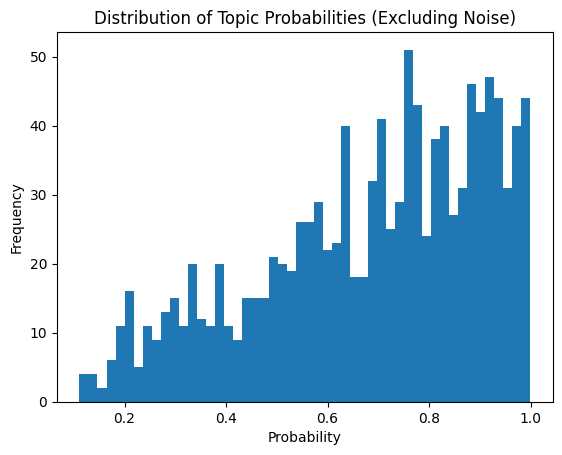

In [83]:
df_topics[(df_topics['Topic'] != -1) & (df_topics['Probability'] < 1)]['Probability'].plot(kind='hist', bins=50, title='Distribution of Topic Probabilities (Excluding Noise)', xlabel='Probability', ylabel='Frequency')

# 3D Cluster Visualization

In [ ]:
import plotly.graph_objects as go

embeddings_3d = umap.UMAP(n_components=3, metric='cosine', random_state=42).fit_transform(enriched_embeddings)
colors = df_topics['Topic'].values

fig1 = go.Figure(
    data=[
        go.Scatter3d(
            x=embeddings_3d[:, 0],
            y=embeddings_3d[:, 1],
            z=embeddings_3d[:, 2],
            mode="markers",
            marker=dict(size=4, opacity=0.8, color=colors, colorscale="Viridis", showscale=True),
        )
    ]
)

fig1.update_layout(
    title="3D Projection of Enriched Embeddings and Topics",
    scene=dict(
        xaxis_title="UMAP Dimension 1",
        yaxis_title="UMAP Dimension 2",
        zaxis_title="UMAP Dimension 3",
    ),
    width=800,
    height=600,
)

fig1.show()


# LLM Topic Labeling

We use again the SDSC vLLM endpoint to get topic labels for the clusters. We use a prompt that asks the LLM to provide a label for each cluster given the TopK closest paragraphs to the cluster centroid (highly relevant paragraphs by means of cosine similarity).

In [71]:
api_key = json.load(open("/myhome/.config/io.datasette.llm/keys.json"))["sdsc-key"]
client = OpenAI(api_key=api_key, base_url="https://vllm-gateway-runai-sharedllm-ralf.inference.compute.datascience.ch/v1/")
client

In [72]:
prompt_template = """
You are analysing a semantic cluster of parliamentary speeches.

The speeches belong to the same semantic embedding cluster, but they may come from different legislative affairs.

Your objective is to identify:

1. the shared argument frame;
2. the policy target discussed in each legislative affair;
3. a natural-language hypothesis that can later be used for Natural Language Inference (NLI).

Important definitions

Argument frame
---------------
The abstract argumentative or procedural pattern shared by the speeches.

Examples:
- implementation timing
- legal certainty
- public health protection
- economic burden
- constitutional competence
- transparency
- procedural scheduling

Canonical policy target
-----------------------
A short noun phrase naming the concrete legislative object.

Examples:
- regulation of smoking rooms and smoking establishments
- expansion of solar energy projects
- transparency requirements for political party financing
- restriction of advertising for small consumer credits

NLI hypothesis
--------------
A complete declarative sentence describing what the legislative proposal does.

The hypothesis MUST express a proposition that could naturally be inferred from a parliamentary speech.

GOOD hypotheses

✓ The proposal regulates smoking rooms and smoking establishments.
✓ The proposal introduces transparency requirements for political party financing.
✓ The proposal expands renewable electricity production.
✓ The proposal restricts advertising for small consumer loans.

BAD hypotheses

✗ The policy target is regulation of smoking rooms.
✗ This cluster concerns smoking regulation.
✗ The topic is passive smoking.
✗ The bill is about renewable energy.

Rules

- Produce concise natural English.
- Avoid meta-language such as:
  "policy target",
  "topic",
  "cluster",
  "legislative affair",
  "this bill concerns".

- The canonical_target must be a noun phrase.

- The nli_hypothesis must be a complete declarative sentence beginning with
  "The proposal..."

- If speeches from different affairs discuss different legislative objects,
  set same_policy_target=false
  and canonical_target=null.

- If the cluster is procedural, mixed or not stance-targetable,
  set target_abstain=true.

Return ONLY valid JSON.

{{
  "argument_frame": "...",
  "same_policy_target": true,
  "canonical_target": "...",
  "nli_hypothesis": "The proposal ...",
  "target_abstain": false,
  "reason": "...",
  "targets_by_affair": [
    {{
      "Affair_ID": 123,
      "canonical_target": "...",
      "nli_hypothesis": "The proposal ...",
      "stance_hypothesis_favor": "The speaker supports ...",
      "stance_hypothesis_against": "The speaker opposes ..."
    }}
  ]
}}

Examples:

{examples_str}
"""

In [73]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.metrics.pairwise import cosine_similarity

def save_json_atomic(data, path):
    path = Path(path)
    tmp_path = path.with_suffix(path.suffix + ".tmp")

    serializable = {str(k): v for k, v in data.items()}

    with open(tmp_path, "w", encoding="utf-8") as f:
        json.dump(serializable, f, ensure_ascii=False, indent=2)

    os.replace(tmp_path, path)


def load_labels_checkpoint(path):
    path = Path(path)

    if not path.exists():
        return {-1: {"canonical_target_en": "Noise", "target_abstain": True}}

    with open(path, "r", encoding="utf-8") as f:
        raw = json.load(f)

    labels = {}
    for k, v in raw.items():
        try:
            key = int(k) if "." not in k else float(k)
        except ValueError:
            key = k
        labels[key] = v

    return labels


def shorten_text(text, max_chars=700):
    text = " ".join(str(text).split())
    if len(text) <= max_chars:
        return text
    return text[:max_chars].rsplit(" ", 1)[0] + " ..."


def extract_json_object(text):
    start = text.find("{")
    end = text.rfind("}")

    if start == -1 or end == -1 or end <= start:
        raise ValueError(f"No JSON object found in response: {text}")

    return json.loads(text[start:end + 1])


def first_nonempty(row, columns, default="Unknown"):
    for col in columns:
        if col in row and pd.notna(row[col]) and str(row[col]).strip():
            return str(row[col]).strip()
    return default


def normalize_policy_target_record(value):
    if not isinstance(value, dict):
        target = None if value in (None, "", "Noise") else str(value).strip()
        return {
            "argument_frame": None,
            "same_policy_target": False,
            "canonical_target_en": target,
            "is_coherent_cluster": bool(target),
            "is_specific_target": bool(target),
            "is_stance_targetable": bool(target),
            "target_abstain": target is None,
            "target_confidence": "low",
            "reason": None,
            "targets_by_affair": [],
        }

    record = value.copy()

    canonical_target = (
        record.get("canonical_target")
        or record.get("canonical_target_en")
        or record.get("nli_target")
    )

    if canonical_target is not None:
        canonical_target = str(canonical_target).strip() or None

    same_policy_target = bool(record.get("same_policy_target", False))
    target_abstain = bool(record.get("target_abstain", not same_policy_target))

    normalized = {
        "argument_frame": record.get("argument_frame"),
        "same_policy_target": same_policy_target,
        "canonical_target_en": canonical_target,
        "nli_hypothesis": record.get("nli_hypothesis"),
        "is_coherent_cluster": bool(record.get("is_coherent_cluster", same_policy_target)),
        "is_specific_target": bool(record.get("is_specific_target", canonical_target is not None)),
        "is_stance_targetable": bool(record.get("is_stance_targetable", not target_abstain)),
        "target_abstain": target_abstain,
        "target_confidence": str(record.get("target_confidence", "low")).lower(),
        "reason": record.get("reason"),
        "targets_by_affair": record.get("targets_by_affair", []),
    }

    if not normalized["same_policy_target"]:
        normalized["canonical_target_en"] = None

    if normalized["canonical_target_en"] is None:
        normalized["target_abstain"] = True

    return normalized


def select_representatives_by_affair(
    cluster_df,
    embeddings,
    docs_per_affair=2,
    max_affairs=5,
    text_col="TEXT_SPAN",
):
    """
    Select representative speeches per Affair_ID.

    The cluster groups speeches by semantic similarity. We then sample the most central
    examples inside each Affair_ID to let the LLM decide whether the shared frame maps
    to one policy target or multiple affair-specific targets.
    """
    if "Affair_ID" not in cluster_df.columns:
        raise ValueError("df must contain an Affair_ID column.")

    representatives = []

    affair_order = (
        cluster_df.groupby("Affair_ID")
        .size()
        .sort_values(ascending=False)
        .head(max_affairs)
        .index
    )

    for affair_id in affair_order:
        subset = cluster_df[cluster_df["Affair_ID"] == affair_id].copy()

        # Use positional locations into the embedding matrix.
        # This assumes cluster_df.index corresponds to embedding row positions.
        subset_positions = subset.index.to_numpy()
        subset_embs = embeddings[subset_positions]

        centroid = subset_embs.mean(axis=0, keepdims=True)
        sims = cosine_similarity(subset_embs, centroid).ravel()

        n_docs = min(docs_per_affair, len(subset))
        top_local_positions = np.argsort(sims)[-n_docs:][::-1]

        reps = subset.iloc[top_local_positions].copy()
        reps["_similarity_to_affair_centroid"] = sims[top_local_positions]

        representatives.append(reps)

    if not representatives:
        return pd.DataFrame(columns=cluster_df.columns)

    return pd.concat(representatives, axis=0)


def build_examples_string(
    cluster_df,
    representative_docs,
    text_col="TEXT_SPAN",
    max_chars=700,
):
    representation = cluster_df["Representation"].iloc[0] if "Representation" in cluster_df.columns else []
    if isinstance(representation, str):
        topic_keywords = representation
    else:
        topic_keywords = " - ".join(map(str, representation))

    example_lines = [
        f"Cluster keywords from BERTopic/c-TF-IDF: {topic_keywords}",
        f"Number of speeches in cluster: {len(cluster_df)}",
        f"Number of affairs represented in cluster: {cluster_df['Affair_ID'].nunique() if 'Affair_ID' in cluster_df.columns else 'Unknown'}",
        "",
    ]

    for affair_id, affair_df in representative_docs.groupby("Affair_ID", sort=False):
        first_row = affair_df.iloc[0]

        bill_title = first_nonempty(
            first_row,
            ["Bill_Title_EN", "Bill_Title_DE", "Bill_Title_FR", "title"],
            default="Unknown bill title",
        )

        bill_number = first_nonempty(
            first_row,
            ["Bill_Number", "Debate_ID"],
            default="Unknown bill number",
        )

        keywords = first_nonempty(
            first_row,
            ["keywords"],
            default="",
        )

        example_lines.append("=" * 80)
        example_lines.append(f"Affair_ID: {affair_id}")
        example_lines.append(f"Bill number: {bill_number}")
        example_lines.append(f"Bill title: {bill_title}")

        if keywords:
            example_lines.append(f"Bill keywords: {shorten_text(keywords, max_chars=300)}")

        example_lines.append("")

        for i, (_, row) in enumerate(affair_df.iterrows(), start=1):
            speaker = first_nonempty(row, ["speaker_fullname", "name"], default="Unknown speaker")
            party = first_nonempty(row, ["party", "party_name"], default="Unknown party")
            role = first_nonempty(row, ["role"], default="Unknown role")
            lang = first_nonempty(row, ["lang", "language_of_text"], default="Unknown language")

            example_lines.append(f"Speech {i}")
            example_lines.append(f"Speaker: {speaker}")
            example_lines.append(f"Party: {party}")
            example_lines.append(f"Role: {role}")
            example_lines.append(f"Language: {lang}")
            example_lines.append("Text:")
            example_lines.append(shorten_text(row[text_col], max_chars=max_chars))
            example_lines.append("")

    return "\n".join(example_lines).strip()


def generate_policy_target_labels(
    df,
    embeddings,
    prompt_template,
    cluster_col="Topic",
    text_col="TEXT_SPAN",
    docs_per_affair=2,
    max_affairs=5,
    system_prompt=None,
    model_name="google/gemma-4-26B-A4B-it",
    checkpoint_path="cluster_policy_targets_checkpoint.json",
    force_rerun=False,
):
    """
    Incrementally labels speech clusters with:

    - shared argument frame
    - whether the cluster has one common policy target
    - policy target per Affair_ID
    - stance hypotheses per affair

    Important:
    Use the same embeddings here that you used to create the clusters.
    If BERTopic was fit with speech_embeddings, pass speech_embeddings here too.
    """
    labels = {
        cluster_id: normalize_policy_target_record(value)
        for cluster_id, value in load_labels_checkpoint(checkpoint_path).items()
    }

    all_clusters = sorted(
        [c for c in df[cluster_col].dropna().unique() if c != -1],
        key=lambda x: (df[cluster_col] == x).sum(),
        reverse=True,
    )

    remaining_clusters = [
        c for c in all_clusters
        if force_rerun or c not in labels
    ]

    print(f"Total clusters: {len(all_clusters)}")
    print(f"Already labeled: {len(all_clusters) - len(remaining_clusters)}")
    print(f"Remaining: {len(remaining_clusters)}")

    try:
        for cluster_id in tqdm(
            remaining_clusters,
            desc="Generating policy target labels",
            miniters=1,
        ):
            cluster_mask = df[cluster_col] == cluster_id
            cluster_df = df.loc[cluster_mask].copy()

            try:
                representative_docs = select_representatives_by_affair(
                    cluster_df=cluster_df,
                    embeddings=embeddings,
                    docs_per_affair=docs_per_affair,
                    max_affairs=max_affairs,
                    text_col=text_col,
                )

                examples_str = build_examples_string(
                    cluster_df=cluster_df,
                    representative_docs=representative_docs,
                    text_col=text_col,
                    max_chars=700,
                )

                prompt = prompt_template.format(examples_str=examples_str)

                response = client.chat.completions.create(
                    model=model_name,
                    messages=[
                        {"role": "system", "content": system_prompt or ""},
                        {"role": "user", "content": prompt},
                    ],
                    temperature=0.0,
                    max_tokens=2048,
                    extra_body={
                        "chat_template_kwargs": {
                            "enable_thinking": False
                        }
                    },
                )

                parsed = extract_json_object(response.choices[0].message.content)
                labels[cluster_id] = normalize_policy_target_record(parsed)

                print(
                    f"Cluster {cluster_id}: "
                    f"frame={labels[cluster_id]['argument_frame']} | "
                    f"same_target={labels[cluster_id]['same_policy_target']} | "
                    f"target={labels[cluster_id]['canonical_target_en']} | "
                    f"abstain={labels[cluster_id]['target_abstain']}"
                )

            except Exception as e:
                labels[cluster_id] = normalize_policy_target_record({
                    "argument_frame": None,
                    "same_policy_target": False,
                    "canonical_target": None,
                    "is_coherent_cluster": False,
                    "is_specific_target": False,
                    "is_stance_targetable": False,
                    "target_abstain": True,
                    "target_confidence": "low",
                    "reason": str(e),
                    "targets_by_affair": [],
                })

                print(f"Error generating label for cluster {cluster_id}: {e}")

            save_json_atomic(labels, checkpoint_path)

    except KeyboardInterrupt:
        save_json_atomic(labels, checkpoint_path)
        print(f"\nInterrupted. Progress saved to {checkpoint_path}.")

    return labels

In [ ]:
# !rm cluster_policy_targets_checkpoint.json

In [75]:
checkpoint_path = "cluster_policy_targets_checkpoint.json"

cluster_label_records = generate_policy_target_labels(
    df=df_topics,
    embeddings=speech_embeddings,
    prompt_template=prompt_template,
    cluster_col="Topic",
    text_col="TEXT_SPAN",
    docs_per_affair=2,
    max_affairs=5,
    checkpoint_path=checkpoint_path,
)

Total clusters: 87
Already labeled: 0
Remaining: 87


Generating policy target labels:   1% 1/87 [00:01<01:56,  1.35s/it]

Cluster 0: frame=constitutional competence | same_target=True | target=marriage for same-sex couples | abstain=False


Generating policy target labels:   2% 2/87 [00:02<01:44,  1.23s/it]

Cluster 3: frame=transparency | same_target=True | target=transparency requirements for political party financing | abstain=False


...

Cluster 120: frame=investment subsidies and funding allocation | same_target=True | target=investment subsidies for hydropower plants | abstain=False


Generating policy target labels:  99% 86/87 [01:50<00:01,  1.25s/it]

Cluster 112: frame=economic and regional impact | same_target=True | target=net-zero greenhouse gas emissions by 2050 | abstain=False


Generating policy target labels: 100% 87/87 [01:51<00:00,  1.28s/it]

Cluster 117: frame=economic and energy security implications | same_target=True | target=net-zero greenhouse gas emissions by 2050 | abstain=False


In [84]:
cluster_label_df = (
    pd.DataFrame.from_dict(cluster_label_records, orient="index")
    .rename_axis("Topic")
    .reset_index()
)

cluster_label_df["Topic"] = pd.to_numeric(cluster_label_df["Topic"], errors="coerce")
cluster_label_df["nli_hypothesis"] = cluster_label_df["nli_hypothesis"]

In [85]:
df_topics_aug = df_topics.merge(cluster_label_df, on="Topic", how="left")

df_topics_aug["target_quality_pass"] = (
    df_topics_aug["is_specific_target"].fillna(False)
    & df_topics_aug["is_stance_targetable"].fillna(False)
    & ~df_topics_aug["target_abstain"].fillna(True)
)

In [86]:
df_valid = df_topics_aug[
    (df_topics_aug["Topic"] != -1)
    & (df_topics_aug["target_quality_pass"])
].copy()

df_valid.to_csv(
    "data_subset_annotated_with_policy_targets.csv",
    index=False,
)

In [88]:
df_valid.head(2).to_dict(orient="records")

[{'Speech_ID': 83164,
  'speaker_uid': 1149.0,
  'speaker_first_name': 'Urs',
  'speaker_last_name': 'Schwaller',
  'speaker_fullname': 'Schwaller Urs',
  'party': 'CVP',
  'party_name': 'Christlichdemokratische Volkspartei der Schweiz',
  'gender': 'm',
  'source_name': 'Online DB',
  'source_abbrev': 'ODB',
  'meeting_uid': 962.0,
  'meeting_number': 2.0,
  'meeting_datetime': '2008-03-04T08:05:00.000000000',
  'meeting_date': '2008-03-04',
  'session_name': 'Spring session',
  'year': 2008.0,
  'legislative_period_uid': 48.0,
  'Debate_ID': '04_476.4',
  'Bill_Number': 4.476,
  'Bill_Title_DE': 'Schutz der Bevölkerung und der Wirtschaft vor dem Passivrauchen',
  'Bill_Title_FR': "Protection de la population et de l'économie contre le tabagisme passif",
  'Bill_Labels': 'Bill|Parliamentary Initiative',
  'Discussion_ID': 13158.0,
  'Partition_ID': 13158.1,
  'Paragraph_ID': 1,
  'name': 'Schwaller Urs',
  'role': 'For the committee',
  'language_of_text': 'DE',
  'TEXT_SPAN': 'Ich be